# Tariff-by-Country-by-Time Construction

Constructs effective (import-weighted) tariff rates by country and date,
tracking the evolution of U.S. tariff policy through 2025-2026.

Each tariff change is documented with its legal authority, executive order /
proclamation number, and a short description, collected in a structured
`TARIFF_ACTIONS` registry.

**Sources:**
- CRS R48549 "Presidential 2025 Tariff Actions: Timeline and Status" (Version 13, January 12, 2026)
- Federal Register, White House fact sheets and executive orders

In [1]:
# Paths in this notebook are relative to the repository root. Opened from its own
# folder, the notebook moves there first; run from the root, this does nothing.
import os
from pathlib import Path
if not Path("tariff-lists").is_dir():
    os.chdir(next(p for p in Path.cwd().parents if (p / "tariff-lists").is_dir()))

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime as dt
import pyarrow as pa
import pyarrow.parquet as pq

## Section 1 — Country List & Baseline Rates

These encode the country-specific reciprocal tariff rates from three stages:
- `tariff` — initial baseline (pre-Aug 7) from EO 14257 Annex I
- `rtariff` — Annex I reciprocal rate (Apr 2 announcement)
- `rtariff-aug` — August 7 updated rates from EO 14326 and bilateral deals

In [3]:
country_list = pd.read_csv('./data/top_50_non_eu.csv', dtype={'CTY_CODE': str})

# Add EU as a bloc
eu_row = pd.DataFrame([{"CTY_NAME": "EUROPEAN UNION", "CTY_CODE": "0003"}])
country_list = pd.concat([country_list, eu_row], ignore_index=True)

# Initial baseline tariff (used for Apr 5 reciprocal activation)
country_list["tariff"] = 10.0
country_list.loc[country_list["CTY_CODE"] == "5700", "tariff"] = 30.0   # China
country_list.loc[country_list["CTY_CODE"] == "5820", "tariff"] = 30.0   # Hong Kong
country_list.loc[country_list["CTY_CODE"] == "1220", "tariff"] = 8.75   # Canada (USMCA-adjusted)
country_list.loc[country_list["CTY_CODE"] == "2010", "tariff"] = 4.5    # Mexico (USMCA-adjusted)
country_list.loc[country_list["CTY_CODE"] == "0003", "tariff"] = 10.0   # EU

# Merge Annex I reciprocal rates
reciprocal = pd.read_csv('./tariff-lists/reciprocal-tariffs-annex-I.csv', dtype={'CTY_CODE': str})
reciprocal.rename(columns={"tariff_rate": "rtariff"}, inplace=True)
country_list = pd.merge(
    left=country_list, right=reciprocal[["rtariff", "CTY_CODE"]],
    on="CTY_CODE", how="left"
)
country_list["rtariff"] = country_list["rtariff"].fillna(10.0)
country_list.loc[country_list["CTY_CODE"] == "5700", "rtariff"] = 34.0  # China
country_list.loc[country_list["CTY_CODE"] == "5820", "rtariff"] = 34.0  # Hong Kong

# Merge August 7 updated rates (from EO 14326 / bilateral letters)
new_list = pd.read_csv('./tariff-lists/clean-august-7-tariffs.csv')
new_list.rename({"country_name": "CTY_NAME"}, axis=1, inplace=True)
country_list = pd.merge(country_list, new_list, on="CTY_NAME", how="left")
country_list["rtariff-aug"] = country_list["rtariff-aug"].fillna(country_list["rtariff"])
country_list.loc[country_list["CTY_NAME"] == "KOREA, SOUTH", "rtariff-aug"] = 15.0
country_list.loc[country_list["CTY_NAME"] == "EUROPEAN UNION", "rtariff-aug"] = 15.0
country_list.loc[country_list["CTY_NAME"] == "INDIA", "rtariff-aug"] = 50.0

## Section 2 — Product-Level Tariff / Exemption Lists

HS-code lists that define which products fall under each tariff action.

In [4]:
exemption_list = pd.read_csv(
    './tariff-lists/annex-II-exemptions.csv', dtype={'HTSUS': str})
# Annex II of EO 14257 — products exempt from reciprocal tariffs. 1,039 HS8
# subheadings; the annex covers every product in a listed 8-digit subheading.
# Built from tariff-lists/sources/Annex-II.pdf by extract-annex-ii.py.

exemption_list_legacy = pd.read_csv(
    './tariff-lists/annex-II-exemptions-legacy.csv', dtype={'HTSUS': str})
# The list used before Oct 27, 2026: 720 of the 1,039 subheadings, padded to
# HS10 and matched on HS10, so it reached only statistical lines ending in 00.
# Kept only for Canada and Mexico, whose Annex II treatment is on hold (see
# _apply_annex_ii_camx_legacy).

exemption_list_phones = pd.read_csv(
    './tariff-lists/consumer_electronics_EO14257_apr11.csv', dtype={'HTSUS': str})
# Apr 11 consumer-electronics exemption

steel_list = pd.read_csv(
    './tariff-lists/steel-tariffs.csv', dtype={'HTSUS': str})
# Section 232 steel products (HS8) — Proclamation 10896

alu_list = pd.read_csv(
    './tariff-lists/alu-tariffs.csv', dtype={'HTSUS': str})
# Section 232 aluminum products (mixed HS8/HS10) — Proclamation 10895
alu_8_list = alu_list[alu_list['HTSUS'].str.len() == 8]

auto_list = pd.read_csv(
    './tariff-lists/auto-tariffs.csv', dtype={'HTSUS': str})
# Section 232 auto tariffs (mixed HS6/HS8/HS10) — Proclamation 10908
auto_6_list = auto_list[auto_list['HTSUS'].str.len() == 6]
auto_8_list = auto_list[auto_list['HTSUS'].str.len() == 8]

copper_list = pd.read_csv(
    './tariff-lists/copper-list.csv', dtype={'HTSUS': str})
# Section 232 copper products (HS8) — Proclamation 10962

brazil_nonaircraft_exemptions = pd.read_csv(
    './tariff-lists/brazil-non-airplane-exemptions.csv', dtype={'HTSUS': str})
brazil_aircraft_exemptions = pd.read_csv(
    './tariff-lists/brazil-airplane-exemptions.csv', dtype={'HTSUS': str})
# Brazil-specific exemptions from EO 14323

brazil_ag_nov13 = pd.read_csv(
    './tariff-lists/brazil-ag-exemptions-nov13.csv', dtype={'HTSUS': str})
# EO 14361 (Nov 20, 2025, retroactive to Nov 13): 238 agricultural subheadings
# plus 11 described articles taken out of the Brazil 40% duty, applied flat by
# HS8. Built by extract-annex-ii.py.

nov_exemptions_list = pd.read_csv(
    './tariff-lists/annex-II-exemptions-nov14.csv', dtype={'HTSUS': str})
# Nov 14 agricultural exemptions (EO 14360)

s122_exempt_list = pd.read_csv(
    './tariff-lists/section122-product-exemptions.csv', dtype={'hts_code': str})
# Section 122 product exemptions, Annex I subdivision (aa)(ii) — 1,098 HS codes
# Covers energy (Ch 27), critical minerals, pharma/chem, ag, electronics,
# fertilizers, bullion, natural rubber, base metals, semiconductors, etc.
s122_exempt_8 = s122_exempt_list[s122_exempt_list['digits'] == 8]['hts_code'].tolist()
s122_exempt_10 = s122_exempt_list[s122_exempt_list['digits'] == 10]['hts_code'].tolist()


# ── April 2026 Section 232 Metals Restructuring (Proclamation, Apr 2, 2026) ──
metals_ia_list = pd.read_csv(
    './tariff-lists/metals-annex-IA.csv', dtype={'HTSUS': str})
# Annex I-A: 50% tier — primary metals + certain derivatives
metals_ia_4  = metals_ia_list[metals_ia_list['HTSUS'].str.len() == 4]['HTSUS'].tolist()
metals_ia_6  = metals_ia_list[metals_ia_list['HTSUS'].str.len() == 6]['HTSUS'].tolist()
metals_ia_8  = metals_ia_list[metals_ia_list['HTSUS'].str.len() == 8]['HTSUS'].tolist()
metals_ia_10 = metals_ia_list[metals_ia_list['HTSUS'].str.len() == 10]['HTSUS'].tolist()

metals_ib_list = pd.read_csv(
    './tariff-lists/metals-annex-IB.csv', dtype={'HTSUS': str})
# Annex I-B: 25% tier — copper articles + steel/alu derivative products
metals_ib_8  = metals_ib_list[metals_ib_list['HTSUS'].str.len() == 8]['HTSUS'].tolist()
metals_ib_10 = metals_ib_list[metals_ib_list['HTSUS'].str.len() == 10]['HTSUS'].tolist()

metals_ii_list = pd.read_csv(
    './tariff-lists/metals-annex-II-removed.csv', dtype={'HTSUS': str})
# Annex II: removed from scope of Section 232
metals_ii_8  = metals_ii_list[metals_ii_list['HTSUS'].str.len() == 8]['HTSUS'].tolist()
metals_ii_10 = metals_ii_list[metals_ii_list['HTSUS'].str.len() == 10]['HTSUS'].tolist()

metals_iii_list = pd.read_csv(
    './tariff-lists/metals-annex-III-temporary.csv', dtype={'HTSUS': str})
# Annex III: temporary ~15% rate through Dec 31, 2027
metals_iii_8  = metals_iii_list[metals_iii_list['HTSUS'].str.len() == 8]['HTSUS'].tolist()
metals_iii_10 = metals_iii_list[metals_iii_list['HTSUS'].str.len() == 10]['HTSUS'].tolist()


# October 2025 Section 232 Timber/Lumber (Proclamation 10976, eff Oct 14 2025)
timber_list = pd.read_csv(
    './tariff-lists/timber-232.csv', dtype={'HTSUS': str})
# Proc 10976 U.S. note 37 annex, 22 codes. Softwood timber/lumber (HS8,
# heading 9903.76.01), upholstered wooden furniture (HS10, 9903.76.02) and
# completed kitchen cabinets/vanities and parts (HS10, 9903.76.03).
timber_softwood  = timber_list.loc[timber_list.category == 'softwood',  'HTSUS'].tolist()
timber_furniture = timber_list.loc[timber_list.category == 'furniture', 'HTSUS'].tolist()
timber_cabinet   = timber_list.loc[timber_list.category == 'cabinet',   'HTSUS'].tolist()


# ── Phase 3 stacked country actions — product lists ──────────────────────
# Phase 3 covers country-level actions that ADD to the rate already in place
# rather than replacing it (Section 301, Section 338). Two kinds of list are
# needed: exemption lists, which carve codes out of an action, and include
# lists, which bound an action to an enumerated basket of codes.
#
# Lists are keyed by list name rather than by regime, so several regimes can
# share one. The three Section 338 actions share a single civil-aircraft
# carve-out, enumerated once in U.S. note 51(d).
#
# Each CSV carries a `category` or `description` column for reporting; only
# the HTSUS column is used for masking.
br301_list = pd.read_csv(
    './tariff-lists/brazil-301-exemptions.csv', dtype={'HTSUS': str})
# USTR Notice of Action, Section 301 — Brazil (Jul 15, 2026), Annex I U.S. note 50
#   flat     (a)(ii)  —  864 codes: beef, coffee, cocoa, petroleum, chemicals,
#                        wood/pulp, natural rubber, non-ferrous metals
#   named    (a)(iii) —   11 codes: etrogs, acai, coconut water, religious-use goods
#   aircraft (a)(iv)  —  546 codes: civil aircraft, engines, parts, simulators
#   pharma   (a)(v)   —  705 codes: articles for pharmaceutical applications

# Section 338 — Canada. Three proclamations of Jul 20, 2026, all effective
# Aug 22, 2026 (originally Aug 19; deferred 3 days by Proclamation 11056 of
# Aug 18, 2026), all 50% ad valorem, sharing a single U.S. note 51. Baskets are
# enumerated inclusion lists and are disjoint from one another.
#   alcohol   9903.03.12 —  63 codes: beverages, some wood and paper
#   dairy     9903.03.13 —  52 codes: milk products, sugars, caseins
#   autos     9903.03.14 — 439 codes: broad retaliation basket across 56
#                          chapters; unrelated to motor vehicles despite the
#                          proclamation's subject
# The civil-aircraft carve-out of note 51(d) (heading 9903.03.16, 554 codes)
# is enumerated once, in the annex that creates note 51, and applies to all
# three. Extracted by extract-338-annex.py; checked by validate-338.py.
ca338_alcohol_list = pd.read_csv(
    './tariff-lists/canada-338-alcohol.csv', dtype={'HTSUS': str})
ca338_dairy_list = pd.read_csv(
    './tariff-lists/canada-338-dairy.csv', dtype={'HTSUS': str})
ca338_autos_list = pd.read_csv(
    './tariff-lists/canada-338-autos.csv', dtype={'HTSUS': str})
ca338_aircraft_list = pd.read_csv(
    './tariff-lists/canada-338-aircraft-exempt.csv', dtype={'HTSUS': str})

# Later proclamations amend the alcohol and autos baskets. Each amended basket
# is a dated version, built by extract-338-annex.py by applying the amending
# Annex II to the basket in force the day before:
#   alcohol  Sep 15, 2026  Proc 11064            -2  +40 -> 101 codes
#            (cheese, hides, furskins, boats)
#   autos    Sep 15, 2026  Proc 11065            -8  +82 -> 513 codes
#            (steel and aluminum structures, furniture, lamps, golf carts)
#   autos    Oct 30, 2026  Proc of Oct 23, 2026  -22 +100 -> 591 codes
#            (cocoa powder, paints, carpets, fiberboard, freezers, valves)
# Five Sep 8 edits narrow an HS8 line to some of its HS10 lines (whisky and
# liqueurs over 4 liters leave; so do some household paper, switchgear and
# fishing-rod lines), so these versions mix HS8 and HS10 codes. Dairy is never
# amended.
ca338_alcohol_0915_list = pd.read_csv(
    './tariff-lists/canada-338-alcohol-2026-09-15.csv', dtype={'HTSUS': str})
ca338_autos_0915_list = pd.read_csv(
    './tariff-lists/canada-338-autos-2026-09-15.csv', dtype={'HTSUS': str})
ca338_autos_1030_list = pd.read_csv(
    './tariff-lists/canada-338-autos-2026-10-30.csv', dtype={'HTSUS': str})


def _split_hs(code_df):
    """Bucket a code list by digit length for HS8/HS10 masking."""
    codes = code_df['HTSUS']
    return {"hs8":  codes[codes.str.len() == 8].tolist(),
            "hs10": codes[codes.str.len() == 10].tolist()}


STACKED_EXEMPT_LISTS = {
    "Brazil-301":          _split_hs(br301_list),
    "Canada-338-aircraft": _split_hs(ca338_aircraft_list),
}

STACKED_INCLUDE_LISTS = {
    "Canada-338-alcohol":            _split_hs(ca338_alcohol_list),
    "Canada-338-alcohol-2026-09-15": _split_hs(ca338_alcohol_0915_list),
    "Canada-338-dairy":              _split_hs(ca338_dairy_list),
    "Canada-338-autos":              _split_hs(ca338_autos_list),
    "Canada-338-autos-2026-09-15":   _split_hs(ca338_autos_0915_list),
    "Canada-338-autos-2026-10-30":   _split_hs(ca338_autos_1030_list),
}


# ── Section 301 forced-labor action — FINAL Notice of Action (Jul 23, 2026) ──
# Notice of Actions, Section 301 forced-labor investigations (Docket USTR-2026-
# 0265/0266), effective 12:01 a.m. ET Jul 24, 2026. Supersedes the provisional
# Jun 5, 2026 determination the model carried until now. Exemptions come from
# Annex II Part A ("Goods of Any Investigated Economy"), the base list that
# applies to every investigated economy, extracted to 301-labor-part-a.csv
# (2,113 codes). The 13 country-specific parts (B-N) and the CAFTA/Jordan
# textile Part O are NOT modeled — see README modeling limitations.
labor301_exempt_list = pd.read_csv(
    './tariff-lists/301-labor-part-a.csv', dtype={'digits': str})
# Annex II Part A scope flags: '' unconditional (856), 'pharma' pharmaceutical-
# application conditional (700), 'aircraft' civil-aircraft GN 6 conditional
# (541), 'ex' subheading limited by description (16).
#
# MODELING CHOICE (Option C): exempt the unconditional AND pharma codes; do NOT
# exempt aircraft or ex.
#   * pharma is applied flat — the Section 122 model already exempts 363 of these
#     same codes as unconditional products, so exempting them keeps labor and the
#     surcharge on the same basis (else labor is heavier than §122 on those lines),
#     and it follows the standing flat-exemption convention for end-use carve-outs.
#     The pharma codes are chemicals (82% chapter 29), so flat application over-
#     exempts their non-pharma use — a modest DOWNWARD bias, smallest for the
#     pharma-heavy exporters (EU, Switzerland, India) it mainly touches.
#   * aircraft and ex are taxed — matching _mask_s122_exempt, which ignores its
#     civil-aircraft codes. These are general industrial goods across 18 chapters
#     (motors, engines, steel, optics) where aircraft use is a small slice, so the
#     over-tax on the genuine aircraft portion is small.
# The full 2,113-code Part A (with scope flags) stays in the CSV for provenance.
_labor_active = labor301_exempt_list[
    labor301_exempt_list['scope_limitation'].fillna('').isin(['', 'pharma'])]
STACKED_EXEMPT_LISTS["Labor-301"] = {
    "hs8":  _labor_active.loc[_labor_active['digits'].str.len() == 8,  'digits'].tolist(),
    "hs10": _labor_active.loc[_labor_active['digits'].str.len() == 10, 'digits'].tolist(),
}


# ── U.S.-China Board of Trade "30-for-30" U.S. import list (Sep 27, 2026) ──
# ANNOUNCED, NOT ENACTED. The White House release of Sep 27, 2026 (Working
# Procedures + Terms of Reference + list, tariff-lists/sources/) approved a list
# of 77 HTS8 codes of Chinese goods "with a view toward providing reduced
# tariff treatment ... consistent with ... domestic legal processes". No rate,
# date, authority or chapter 99 heading exists yet, so the list is loaded here
# but the regime that uses it is staged OFF (CHINA_30FOR30_LIVE, Section 3).
#
# china-30for30-us-import-list.csv is the list as printed (provenance).
# china-30for30-model-list.csv is the engine form: 70 HS8 codes plus the 13
# HTS10 statistical lines that resolve the seven juvenile-furniture "Ex-Out"
# rows (highchairs/boosters, infant walkers, bouncers, swings, child safety
# seats, play yards) to exactly the products their descriptions name. The one
# ex-out NOT resolvable at HS10 — 9503.00.00 toys, which excludes items
# "enabled with radio frequency, Wi-Fi, Ethernet, or Bluetooth" — is applied
# flat (a small over-inclusion, documented in the README). Built by
# extract-china-30for30.py; guarded by validate-china-30for30.py.
china_30for30_list = pd.read_csv(
    './tariff-lists/china-30for30-model-list.csv', dtype={'HTSUS': str})
STACKED_INCLUDE_LISTS["China-30for30"] = _split_hs(china_30for30_list)


# ── Per-HS10 statutory MFN for the Section 301 net-of-MFN cap ─────────────
# Column-1 (general) MFN rate per 10-digit HTS code: HTS statutory where the rate
# is a clean ad valorem, pooled 2024 customs AVE as a fallback for specific/compound
# duties (built and validated in mfn-per-code-comparison.ipynb). Used by the phase-3
# net-of-MFN labor regimes to charge 301 = max(0, cap - MFN). Keyed by HS10 string.
mfn_per_code = pd.read_csv('./tariff-lists/mfn-per-code.csv', dtype={'HS10': str})
MFN_BY_HS10 = dict(zip(mfn_per_code['HS10'], mfn_per_code['mfn_final_pct']))


## Section 2b — Import Data Functions

Functions to download HS10-level import data from the Census API and load
cached parquet files. The `year` parameter controls the weight year —
set to 2024 by default but can be changed to e.g. 2025 to use updated
trade flows as weights.

To re-download, uncomment and run:
```python
download_all_imports(country_list, year=2024)
```

In [5]:
# ── Import Data: Download and Load Functions ─────────────────────────────

CENSUS_API_KEY = "34e40301bda77077e24c859c6c6c0b721ad73fc7"

def download_imports(cnty_code, year=2024, api_key=CENSUS_API_KEY):
    """
    Pull HS10-level import data from the Census API for a given country
    and December of the specified year. Computes import shares (weights).
    
    Parameters
    ----------
    cnty_code : str — Census country code
    year : int — year for import weights (e.g. 2024, 2025)
    api_key : str — Census API key
    
    Returns
    -------
    df : DataFrame with columns including HS10, HS8, HS6, imports, duty, share
    """
    import requests
    
    time_period = f"{year}-12"
    
    url = (
        f"https://api.census.gov/data/timeseries/intltrade/imports/hs"
        f"?get=CTY_NAME,CON_VAL_YR,CAL_DUT_YR,I_COMMODITY,I_COMMODITY_SDESC"
        f"&key={api_key}"
        f"&time={time_period}"
        f"&COMM_LVL=HS10"
        f"&CTY_CODE={cnty_code}"
    )
    
    r = requests.get(url)
    r.raise_for_status()
    
    df = pd.DataFrame(r.json()[1:], columns=r.json()[0])
    
    df["time"] = pd.to_datetime(df["time"], format="%Y-%m")
    df["imports"] = df["CON_VAL_YR"].astype(float)
    df["duty"] = df["CAL_DUT_YR"].astype(float)
    df["share"] = df["imports"] / df["imports"].sum()
    df["HS10"] = df["I_COMMODITY"].astype(str)
    df["HS8"] = df["HS10"].str[0:8]
    df["HS6"] = df["HS10"].str[0:6]
    
    return df


def download_all_imports(country_list, year=2024, api_key=CENSUS_API_KEY, data_dir="./data"):
    """
    Download HS10 import data for all countries and cache as parquet files.
    File naming convention: {data_dir}/{year}-hs10-imports{CTY_CODE}.parquet
    
    Parameters
    ----------
    country_list : DataFrame — must have 'CTY_CODE' column
    year : int — year for import weights
    api_key : str — Census API key
    data_dir : str — directory for parquet files
    """
    import pyarrow as pa
    import pyarrow.parquet as pq
    
    for _, row in country_list.iterrows():
        print(f"Downloading {row.get('CTY_NAME', row['CTY_CODE'])}...")
        df = download_imports(row['CTY_CODE'], year=year, api_key=api_key)
        outfile = f"{data_dir}/{year}-hs10-imports{row['CTY_CODE']}.parquet"
        pq.write_table(pa.Table.from_pandas(df), outfile)
    
    print("Done.")


def load_imports(cnty_code, year=2024, data_dir="./data"):
    """
    Load cached HS10-level import data from parquet.
    
    Parameters
    ----------
    cnty_code : str — Census country code
    year : int — weight year (must match what was downloaded)
    data_dir : str — directory for parquet files
    
    Returns
    -------
    df : DataFrame
    """
    infile = f"{data_dir}/{year}-hs10-imports{cnty_code}.parquet"
    return pq.read_table(infile).to_pandas()

## Section 3 — Tariff Action Registry

Each action is a dict carrying its legal authority, EO/Proclamation reference,
description, and an apply function that mutates the tariff column.

Actions are applied in chronological order — later actions overwrite earlier ones.

### Legal Authorities

| Authority | Statute | Scope |
|-----------|---------|-------|
| **IEEPA** | 50 U.S.C. §§1701 et seq. | Country-level tariffs declared under national emergency (fentanyl, trade deficit, Brazil, India oil) |
| **Section 232** | 19 U.S.C. §1862 | Sector-specific tariffs based on national security threat finding (steel, aluminum, autos, copper, timber, trucks, semiconductors) |
| **Section 301** | 19 U.S.C. §§2411-20 | Retaliatory tariffs for unfair trade practices (China legacy tariffs from 2018-19; captured in 2024 baseline, not in this model) |

> **Note (Feb 20, 2026):** The Supreme Court ruled 6-3 in *V.O.S. Selections v. United States*
> that IEEPA does not authorize the President to impose tariffs. This invalidates all
> IEEPA-based tariffs. Section 232 tariffs remain in effect. This registry reflects tariffs
> *as imposed* through each action date.

In [6]:
# ── Product-group masks ──────────────────────────────────────────────────

def _mask_steel(df):
    return df["HS8"].isin(steel_list["HTSUS"].tolist())

def _mask_alu(df):
    return (df["HS10"].isin(alu_list["HTSUS"].tolist())
            | df["HS8"].isin(alu_8_list["HTSUS"].tolist()))

def _mask_auto(df):
    return (df["HS8"].isin(auto_8_list["HTSUS"].tolist())
            | df["HS10"].isin(auto_list["HTSUS"].tolist())
            | df["HS6"].isin(auto_6_list["HTSUS"].tolist()))

def _mask_copper(df):
    return df["HS8"].isin(copper_list["HTSUS"].tolist())

def _mask_exemptions(df):
    return df["HS8"].isin(exemption_list["HTSUS"].tolist())

def _mask_exemptions_legacy(df):
    return df["HS10"].isin(exemption_list_legacy["HTSUS"].tolist())

def _mask_phones(df):
    return df["HS10"].isin(exemption_list_phones["HTSUS"].tolist())

def _mask_brazil_non_aircraft(df):
    return df["HS8"].isin(brazil_nonaircraft_exemptions["HTSUS"].tolist())

def _mask_brazil_aircraft(df):
    return df["HS8"].isin(brazil_aircraft_exemptions["HTSUS"].tolist())

def _mask_brazil_ag_nov13(df):
    return df["HS8"].isin(brazil_ag_nov13["HTSUS"].tolist())

def _mask_nov_exemptions(df):
    return df["HS8"].isin(nov_exemptions_list["HTSUS"].tolist())

def _mask_232_2025(df):
    """Section 232 sectors in force during the IEEPA period that phase-2
    actions must not overwrite. Timber runs after these actions in the
    registry, so it overrides them on its own."""
    return _mask_steel(df) | _mask_alu(df) | _mask_auto(df) | _mask_copper(df)

def _mask_s122_exempt(df):
    """Products exempt from Section 122 surcharge under Annex I (aa)(ii).
    Mixed HS8 (1,097 codes) and HS10 (1 code: 8505110070 NdFeB magnets).
    Aircraft exemptions (aa)(iv) are ignored — see design notes."""
    return df["HS8"].isin(s122_exempt_8) | df["HS10"].isin(s122_exempt_10)


# ── April 2026 Metals Restructuring Masks ────────────────────────────────

def _mask_annex_IA(df):
    """Annex I-A: 50% tier. Mixed HS4/HS6/HS8/HS10 codes."""
    return (df["HS10"].isin(metals_ia_10)
            | df["HS8"].isin(metals_ia_8)
            | df["HS6"].isin(metals_ia_6)
            | df["HS8"].str[:4].isin(metals_ia_4))

def _mask_annex_IB(df):
    """Annex I-B: 25% tier. HS8/HS10 codes."""
    return (df["HS10"].isin(metals_ib_10)
            | df["HS8"].isin(metals_ib_8))

def _mask_annex_II_removed(df):
    """Annex II: removed from scope. HS8/HS10 codes."""
    return (df["HS10"].isin(metals_ii_10)
            | df["HS8"].isin(metals_ii_8))

def _mask_annex_III(df):
    """Annex III: temporary ~15% rate. HS8/HS10 codes."""
    return (df["HS10"].isin(metals_iii_10)
            | df["HS8"].isin(metals_iii_8))

def _is_alu_chapter(df):
    """Helper: True for products in HS Chapter 76 (aluminum).
    Used to identify Russian aluminum for the 200% rate (Clause 8)."""
    return df["HS8"].str[:2] == "76"


# October 2025 Timber/Lumber masks (Proclamation 10976)

def _mask_timber_softwood(df):
    """Softwood timber & lumber (9903.76.01). HS8 codes."""
    return df["HS8"].isin(timber_softwood)

def _mask_timber_furniture(df):
    """Upholstered wooden furniture (9903.76.02). HS10 codes."""
    return df["HS10"].isin(timber_furniture)

def _mask_timber_cabinet(df):
    """Completed kitchen cabinets & vanities & parts (9903.76.03). HS10 codes."""
    return df["HS10"].isin(timber_cabinet)

def _mask_timber(df):
    """Union of the Section 232 timber sector (Proclamation 10976)."""
    return (_mask_timber_softwood(df) | _mask_timber_furniture(df)
            | _mask_timber_cabinet(df))


# ── Section 232 union + Section 301 exemption masks ──────────────────────

def _mask_all_232(df):
    """Union of every Section 232 product set the model tracks.

    Used to carve 232 goods out of the Section 122 surcharge and out of the
    phase-3 stacked country actions (Section 301 note 50(a)(vi), Section 338
    note 51(c)), both of which exempt goods already subject to 232.

    Covers timber (Proc 10976) as of Jul 23, 2026. Does NOT cover
    medium/heavy-duty vehicles
    (Proc 10984), semiconductors (Proc 11002), or patented pharmaceuticals —
    those actions are not modeled, so their goods are treated as non-232."""
    return (_mask_steel(df) | _mask_alu(df) | _mask_auto(df) | _mask_copper(df)
            | _mask_annex_IA(df) | _mask_annex_IB(df) | _mask_annex_III(df)
            | _mask_timber(df))


def _mask_stacked_exempt(df, list_name):
    """Product exemptions from a phase-3 stacked country action.

    Pools every exemption category in the named list: for Section 301 the flat
    subheading list, named articles, civil aircraft and pharmaceutical-
    application articles; for Section 338 the civil-aircraft carve-out of
    U.S. note 51(d).

    Approximation: aircraft exemptions are conditional on meeting HTSUS general
    note 6, and the Brazil pharmaceutical exemption applies only to
    pharmaceutical end uses. Neither condition is resolvable from HS10 import
    data, so both are applied flat to every listed code. This over-exempts."""
    codes = STACKED_EXEMPT_LISTS[list_name]
    return df["HS8"].isin(codes["hs8"]) | df["HS10"].isin(codes["hs10"])


def _mask_stacked_include(df, list_name):
    """Products an inclusion-scoped phase-3 action reaches.

    Section 301 actions cover all goods of a country except an exemption list.
    Section 338 actions instead reach only the codes enumerated in their annex,
    so those regimes carry an include list and this mask bounds them."""
    codes = STACKED_INCLUDE_LISTS[list_name]
    return df["HS8"].isin(codes["hs8"]) | df["HS10"].isin(codes["hs10"])


def _mask_patented_pharma(df):
    """Placeholder: patented pharmaceutical articles (headings 9903.04.60-.66).

    That Section 232 action is not modeled and no HS list exists, so this
    matches nothing. It exists so the Jul 31, 2026 amendment to the Brazil
    301 carve-out has somewhere to attach if the list is added later."""
    return pd.Series(False, index=df.index)


def _mask_cafta_textile(df):
    """CAFTA-DR duty-free textiles and apparel (HTSUS chapters 50-63).

    Annex A of the Section 301 labor notice exempts textiles/apparel that enter
    duty-free under CAFTA-DR from Costa Rica, the Dominican Republic, El
    Salvador, Guatemala, Honduras and Nicaragua. Whether a given entry actually
    claimed CAFTA-DR duty-free treatment is not resolvable from HS10 import
    data, so the exemption is applied flat to all of chapters 50-63 for those
    six countries. This OVER-EXEMPTS: it also frees textile trade that entered
    under MFN or another program. Documented as a modeling limitation."""
    ch = df["HS8"].str[:2]
    return ch.isin([f"{c:02d}" for c in range(50, 64)])


In [7]:
# ── Phase 1: Base country-level rate functions ──────────────────────────
# These set the IEEPA layer (blanket country rates).
# Phase 2 sector overrides will stamp on top of these.

def _apply_fentanyl_feb(df, cty, rate):
    """Feb 4: IEEPA fentanyl tariffs — 20% on China/HK."""
    df["tariff"] = 0.0
    if cty in ("5700", "5820"):
        df["tariff"] = 20.0
    return df


def _apply_usmca_march(df, cty, rate):
    """Mar 6: USMCA carve-outs. Canada 8.75%, Mexico 4.5%; China/HK 20%."""
    df["tariff"] = 0.0
    if cty in ("5700", "5820"):
        df["tariff"] = 20.0
    elif cty == "1220":
        df["tariff"] = 8.75
    elif cty == "2010":
        df["tariff"] = 4.5
    return df


def _apply_reciprocal_apr5(df, cty, rate):
    """Apr 5: Reciprocal tariffs activate at the 10% baseline (EO 14257 s.3(a)).
    The Annex I country rates do not start until Apr 9."""
    df["tariff"] = 10.0
    if cty in ("5700", "5820"):
        df["tariff"] = 10.0 + 20.0  # fentanyl stacks
    elif cty == "1220":
        df["tariff"] = 8.75
    elif cty == "2010":
        df["tariff"] = 4.5
    return df


def _apply_country_rates_apr9(df, cty, rate):
    """Apr 9: Annex I country rates take effect (EO 14257 s.3(a)); China/HK at
    84% reciprocal after EO 14259 (+20% fentanyl = 104%). They last one day:
    the Apr 10 pause replaces them."""
    df["tariff"] = rate
    if cty in ("5700", "5820"):
        df["tariff"] = 84.0 + 20.0
    elif cty == "1220":
        df["tariff"] = 8.75
    elif cty == "2010":
        df["tariff"] = 4.5
    return df


def _apply_90day_pause(df, cty, rate):
    """Apr 10: 90-day pause (EO 14266). Universal 10%; China/HK reciprocal
    raised to 125% (+20% fentanyl = 145%)."""
    df["tariff"] = 10.0
    if cty in ("5700", "5820"):
        df["tariff"] = 125.0 + 20.0
    elif cty == "1220":
        df["tariff"] = 8.75
    elif cty == "2010":
        df["tariff"] = 4.5
    return df


def _apply_geneva_deal(df, cty, rate):
    """May 12: Geneva deal — China from 145% to 30% (10% recip + 20% fentanyl)."""
    df["tariff"] = 10.0
    if cty == "1220":
        df["tariff"] = 8.75
    elif cty == "2010":
        df["tariff"] = 4.5
    elif cty in ("5700", "5820"):
        df["tariff"] = 30.0
    return df


def _apply_august_base_rates(df, cty, rate):
    """Aug 7: Country-specific reciprocal rates from EO 14326.
    Canada fentanyl increased to 35% (EO 14325).
    Brazil +40% (EO 14323)."""
    df["tariff"] = rate
    if cty == "1220":  # Canada
        df["tariff"] = (8.75 / 25.0) * 35.0
    if cty == "3510":  # Brazil
        df["tariff"] = 50.0
    return df


def _apply_november_china_base(df, cty, rate):
    """Nov 1: China fentanyl reduced 20% -> 10%.
    Net China rate: 10% reciprocal + 10% fentanyl = 20%.
    Canada fentanyl rate scaled up."""
    if cty in ("5700", "5820"):
        df["tariff"] = 20.0  # hardcoded: 10% reciprocal + 10% fentanyl
    if cty == "1220":
        df["tariff"] = (8.75 / 25.0) * 45.0
    return df


def _apply_november_swiss_base(df, cty, rate):
    """Nov 14: Switzerland rate capped at 15%."""
    if cty == "4419":
        df["tariff"] = 15.0
    return df


def _apply_korea_base(df, cty, rate):
    """Dec 4: South Korea deal — 15% reciprocal ceiling."""
    if cty == "5800":
        df["tariff"] = 15.0
    return df


def _apply_india_deal(df, cty, rate):
    """Feb 7, 2026: India — Russian oil tariff removed, reciprocal to 18%."""
    if cty == "5330":
        df["tariff"] = 18.0
    return df


def _apply_scotus_base(df, cty, rate):
    """Feb 20, 2026: EO revoking all IEEPA ad valorem duties.
    Revokes EO 14193/14194/14195 (fentanyl), EO 14257 (reciprocal),
    EO 14323 (Brazil), and all bilateral amendments.
    Section 232 and Section 301 duties are explicitly preserved."""
    df["tariff"] = 0.0
    return df


# ── Phase 2: Sector overrides and exemptions ────────────────────────────
# These stamp on top of the phase-1 base rates. Section 232 tariffs and
# product exemptions are applied here so they are never wiped by IEEPA
# base-rate resets.

def _apply_steel_alu_25(df, cty, rate):
    """Mar 12: Section 232 steel and aluminum at 25%."""
    df.loc[_mask_steel(df), "tariff"] = 25.0
    df.loc[_mask_alu(df), "tariff"] = 25.0
    return df


def _apply_auto_initial(df, cty, rate):
    """Apr 3: Section 232 autos at 25% (Canada/Mexico exempt)."""
    
    if cty in ("1220", "2010"):       # Canada/Mexico — seem lower
        df.loc[_mask_auto(df), "tariff"] = 15.0
    else:
        df.loc[_mask_auto(df), "tariff"] = 25.0

    return df
    # if cty not in ("1220", "2010"): # previous version: all non-Canada/Mexico autos at 25%
    #     df.loc[_mask_auto(df), "tariff"] = 25.0
    # return df


def _apply_phone_exemption(df, cty, rate):
    """Apr 11: Consumer electronics exempt (China/HK still pay fentanyl 20%)."""
    phones = _mask_phones(df)
    if cty in ("5700", "5820"):
        df.loc[phones, "tariff"] = 20.0
    else:
        df.loc[phones, "tariff"] = 0.0
    return df


def _apply_annex_ii(df, cty, rate):
    """Apr 5: Annex II exemptions from reciprocal tariffs.

    Annex II exempts goods only from "the ad valorem rates of duty under this
    order" (EO 14257 s.3(b)), so other IEEPA duties still apply:
      * China/HK keep the 20% fentanyl duty (10% from Nov 1, see
        _apply_china_fentanyl_cut_exempt).
      * Brazil keeps its 40% from Aug 7, see _apply_brazil_layers.
      * India's Russian-oil 25% also exempts Annex II goods (heading
        9903.01.86), so India's go to 0% like everyone else's.
    Canada and Mexico are on hold and handled by _apply_annex_ii_camx_legacy."""
    if cty in ("1220", "2010"):
        return df
    exempt = _mask_exemptions(df)
    if cty in ("5700", "5820"):  # China/HK — fentanyl 20% still applies
        df.loc[exempt, "tariff"] = 20.0
    else:
        df.loc[exempt, "tariff"] = 0.0
    return df


def _apply_annex_ii_camx_legacy(df, cty, rate):
    """Apr 11: Canada/Mexico keep the pre-Oct 2026 Annex II treatment.

    HOLD (Oct 27, 2026). Annex II exempts goods from the reciprocal tariff,
    which never applied to Canada or Mexico (EO 14257 s.3(d)-(e)), so by law
    it changes nothing for them. Until their treatment is decided they keep
    the legacy list (HS10 match) and Apr 11 start, so their published rates
    do not move."""
    if cty in ("1220", "2010"):
        df.loc[_mask_exemptions_legacy(df), "tariff"] = 0.0
    return df


def _apply_steel_alu_50(df, cty, rate):
    """Jun 3: Steel/aluminum doubled to 50%. UK stays at 25% per deal."""
    if cty == "4120":  # UK
        df.loc[_mask_steel(df), "tariff"] = 25.0
        df.loc[_mask_alu(df), "tariff"] = 25.0
    else:
        df.loc[_mask_steel(df), "tariff"] = 50.0
        df.loc[_mask_alu(df), "tariff"] = 50.0
    return df


def _apply_brazil_layers(df, recip_exempt, b40_exempt):
    """Brazil's two IEEPA duties have separate exemption lists.

    Annex II and the electronics exemption remove only the 10% reciprocal
    duty. The 40% (EO 14323) applies unless the good is in that order's own
    Annex I, which in turn removes only the 40% (CBP CSMS 65807735). Section
    232 goods pay neither (EO 14323 s.3(a)) and keep their 232 rate."""
    hit = (recip_exempt | b40_exempt) & ~_mask_232_2025(df)
    layered = 10.0 * ~recip_exempt + 40.0 * ~b40_exempt
    df.loc[hit, "tariff"] = layered[hit]
    return df


def _apply_august_sectors(df, cty, rate):
    """Aug 7: Copper 50% (Proc 10962); auto deals; Brazil exemptions."""
    # Section 232: Copper at 50%
    df.loc[_mask_copper(df), "tariff"] = 50.0

    # Section 232: Auto deals (bilateral adjustments to Proc 10908)
    auto = _mask_auto(df)
    if cty in ("1220", "2010"):       # Canada/Mexico — seem to be at 15%
        df.loc[auto, "tariff"] = 15.0
    elif cty == "5880":               # Japan — 15%
        df.loc[auto, "tariff"] = 15.0
    elif cty == "0003":               # EU — 15%
        df.loc[auto, "tariff"] = 15.0
    elif cty == "5800":               # South Korea — 15%
        df.loc[auto, "tariff"] = 15.0
    else:
        df.loc[auto, "tariff"] = 25.0

    # Brazil: the 10% reciprocal and the 40% (EO 14323) are separate layers
    if cty == "3510":
        _apply_brazil_layers(
            df,
            recip_exempt=_mask_exemptions(df) | _mask_phones(df),
            b40_exempt=_mask_brazil_non_aircraft(df) | _mask_brazil_aircraft(df))

    return df


def _apply_china_fentanyl_cut_exempt(df, cty, rate):
    """Nov 1: China/HK goods exempt from the reciprocal tariff (Annex II,
    electronics) pay only the fentanyl duty, now 10% (EO 14357)."""
    if cty in ("5700", "5820"):
        exempt = (_mask_exemptions(df) | _mask_phones(df)) & ~_mask_232_2025(df)
        df.loc[exempt, "tariff"] = 10.0
    return df


def _apply_november_ag_phones(df, cty, rate):
    """Nov 14: Annex II widened to agricultural goods (EO 14360).

    China/HK keep the 10% fentanyl duty on them. Brazil's 40% stays unless the
    good is on EO 14361's list (Nov 20, retroactive to Nov 13)."""
    nov = _mask_nov_exemptions(df)
    if cty in ("5700", "5820"):
        df.loc[nov, "tariff"] = 10.0
    elif cty == "3510":
        _apply_brazil_layers(
            df,
            recip_exempt=nov | _mask_exemptions(df) | _mask_phones(df),
            b40_exempt=(_mask_brazil_non_aircraft(df) | _mask_brazil_aircraft(df)
                        | _mask_brazil_ag_nov13(df)))
    else:
        df.loc[nov, "tariff"] = 0.0
    return df


def _apply_korea_auto(df, cty, rate):
    """Dec 4: South Korea auto deal at 15%."""
    if cty == "5800":
        df.loc[_mask_auto(df), "tariff"] = 15.0
    return df


def _apply_scotus_sectors(df, cty, rate):
    """Feb 20, 2026: Re-apply only surviving Section 232 tariffs.
    All IEEPA tariffs revoked by EO; 232 explicitly preserved."""
    # Steel 50% (UK 25%) — Proc 10896/10947
    steel = _mask_steel(df)
    if cty == "4120":
        df.loc[steel, "tariff"] = 25.0
    else:
        df.loc[steel, "tariff"] = 50.0

    # Aluminum 50% (UK 25%) — Proc 10895/10947
    alu = _mask_alu(df)
    if cty == "4120":
        df.loc[alu, "tariff"] = 25.0
    else:
        df.loc[alu, "tariff"] = 50.0

    # Autos with deal rates — Proc 10908 as amended
    auto = _mask_auto(df)
    if cty in ("1220", "2010"):
        df.loc[auto, "tariff"] = 15.0 # seem to be about 15%
    elif cty == "4120":
        df.loc[auto, "tariff"] = 10.0
    elif cty in ("5880", "0003", "5800"):
        df.loc[auto, "tariff"] = 15.0
    else:
        df.loc[auto, "tariff"] = 25.0

    # Copper 50% — Proc 10962
    df.loc[_mask_copper(df), "tariff"] = 50.0

    # IEEPA phone exemption and fentanyl surcharge on phones both struck down —
    # zero out any phone rate set by earlier phase-2 actions
    df.loc[_mask_phones(df), "tariff"] = 0.0

    return df



# ── Section 122 Temporary Import Surcharge (Feb 24, 2026) ───────────────

def _apply_s122_base(df, cty, rate):
    """Feb 24, 2026: Section 122 temporary import surcharge — 10% universal.
    Authority: Section 122, Trade Act of 1974 (balance-of-payments emergency).
    Duration: 150 days (through Jul 24, 2026) unless extended by Congress.
    Canada/Mexico USMCA-compliant goods are exempt per (aa)(vi)/(vii);
    we treat all Canada/Mexico imports as USMCA-eligible (same simplification
    used throughout)."""
    if cty in ("1220", "2010"):  # Canada, Mexico — USMCA exempt
        pass  # tariff stays at 0 from ieepa_revocation_base
    else:
        df["tariff"] = 10.0 
        #df["tariff"] = 15.0 # I went to the Edina Girls 3rd place State Hockey Game
                            # came back and found out I had to change it to 15%
    return df


def _apply_s122_exemptions(df, cty, rate):
    """Feb 24, 2026: Zero out Section 122 product exemptions from Annex I (aa)(ii).
    These 1,098 HS codes cover energy, critical minerals, pharma, ag, electronics,
    fertilizers, bullion, semiconductors, etc.
    Section 232 products are explicitly carved out of the surcharge per (aa)(v) —
    they keep their 232 rates and pay 0% surcharge on covered content."""
    if cty in ("1220", "2010"):
        return df  # Already fully exempt via USMCA
    exempt = _mask_s122_exempt(df)
    df.loc[exempt & ~_mask_all_232(df), "tariff"] = 0.0
    return df



# ── April 2026 Section 232 Metals Tiered Restructuring ──────────────────

def _apply_metals_restructuring(df, cty, rate):
    """Apr 6, 2026: Section 232 metals tiered restructuring.
    Replaces flat 50% with tiered system per Proclamation of Apr 2, 2026.
    
    Clause (2): Annex I-A → 50% (UK 25%)
    Clause (3): Annex I-B → 25% (UK 15%)
    Clause (5): Annex III → ~15% flat approx (temporary through Dec 31, 2027)
    Clause (4): Annex II → 0% (removed from scope)
    Clause (8): Russian aluminum → 200% (Proc 10522, unchanged)
    Clause (9): Products on multiple lists pay once, not combined
    Clause (10): Prior bilateral auto agreements preserved — skip autos
    """
    # Identify auto products to skip (Clause 10: does not alter prior agreements)
    auto = _mask_auto(df)

    # --- Annex I-A: 50% tier (Clause 2) ---
    ia = _mask_annex_IA(df) & ~auto
    if cty == "4120":       # UK: 25% per Clause (2)(b)
        df.loc[ia, "tariff"] = 25.0
    elif cty == "4621":     # Russia
        # Clause (8): ALL Russian aluminum at 200% (Proc 10522)
        df.loc[ia & _is_alu_chapter(df), "tariff"] = 200.0
        df.loc[ia & ~_is_alu_chapter(df), "tariff"] = 50.0
    else:
        df.loc[ia, "tariff"] = 50.0

    # --- Annex I-B: 25% tier (Clause 3) ---
    ib = _mask_annex_IB(df) & ~auto & ~ia  # Clause (9): single application
    if cty == "4120":       # UK: 15% per Clause (3)(b)
        df.loc[ib, "tariff"] = 15.0
    elif cty == "4621":     # Russia
        df.loc[ib & _is_alu_chapter(df), "tariff"] = 200.0  # Clause (8)
        df.loc[ib & ~_is_alu_chapter(df), "tariff"] = 25.0
    else:
        df.loc[ib, "tariff"] = 25.0

    # --- Annex III: temporary ~15% (Clause 5, expires Dec 31, 2027) ---
    # Flat 15% approximation; true rate = max(0, 15% - Column1 MFN duty)
    iii = _mask_annex_III(df) & ~auto & ~ia & ~ib  # single application
    if cty == "4621":       # Russia: Clause (5)(c) → 25% (non-NTR)
        df.loc[iii & _is_alu_chapter(df), "tariff"] = 200.0  # Clause (8)
        df.loc[iii & ~_is_alu_chapter(df), "tariff"] = 25.0
    else:
        df.loc[iii, "tariff"] = 15.0

    # --- Annex II: removed from scope (Clause 4) ---
    ii = _mask_annex_II_removed(df) & ~auto
    df.loc[ii, "tariff"] = 0.0

    return df


def _apply_annex_III_expiry(df, cty, rate):
    """Jan 1, 2028: Annex III temporary reductions expire (Clause 7).
    Products revert to Annex I-B rates (Clause 3): 25% (UK 15%)."""
    auto = _mask_auto(df)
    ia = _mask_annex_IA(df)
    iii = _mask_annex_III(df) & ~auto & ~ia

    if cty == "4120":       # UK
        df.loc[iii, "tariff"] = 15.0
    elif cty == "4621":     # Russia
        df.loc[iii & _is_alu_chapter(df), "tariff"] = 200.0
        df.loc[iii & ~_is_alu_chapter(df), "tariff"] = 25.0
    else:
        df.loc[iii, "tariff"] = 25.0

    return df


# ── Phase 3: Stacked country actions (Section 301, Section 338) ─────────
# Phase 3 holds country-level actions that ADD to the rate already in place
# rather than replacing it, and that carve out goods already subject to
# Section 232. Both properties require them to run after phase 2.
#
# Two legal authorities sit here, both of which survived the Feb 20, 2026
# SCOTUS ruling on IEEPA:
#   Section 301 (19 U.S.C. 2411) — stacks per U.S. note 50(a)(i)
#   Section 338 (19 U.S.C. 1338) — stacks per U.S. note 51(a)
#
# They differ in exactly one respect, captured by "scope":
#   "all"     covers every good of the country except an exemption list
#             (Section 301)
#   "listed"  covers only the codes enumerated in the action's annex
#             (Section 338)
#
# Every action in this phase is additive, so they commute — order within the
# phase does not matter, and a country may carry several at once.
#
# To add an action: extract its code list, register it in Section 2, and
# append one entry here. No new logic is required.
#
# To amend one: give the existing entry an end_date (the last day it applies,
# inclusive) and append a new entry starting the next day with its own basket
# and carve-outs. Editing an entry in place would rewrite every earlier date.
#
# Section 338 Canada: Proclamation 11056 (Aug 18, 2026; FR Doc 2026-17294)
# suspended the three actions for 3 days while negotiations ran, amending the
# Annex II chapeau of Procs 11046/11047/11048 from "August 19, 2026" to
# "August 22, 2026". Negotiations failed and the duties took effect Aug 22.
# Nothing else changed (same baskets, rate, note 51 carve-outs), so this is
# modeled purely as the effective_date below.
#
# Section 338 Canada has since been amended twice, so alcohol and autos are
# split into dated versions (dairy is never amended):
#   Sep 15, 2026 — Procs 11064/11065 (Sep 8) change the alcohol and autos
#     baskets and rewrite note 51(c) so that its Section 232 exemption names
#     only heading 9903.03.13. From Sep 15 the alcohol and autos duties apply
#     in addition to Section 232; dairy keeps the exemption.
#   Oct 30, 2026 — the Proclamation of Oct 23, 2026 changes the autos basket
#     again. Still in addition to Section 232.
# Procs 11061-11063 (Sep 8) also ban some basket goods from importation from
# Sep 29: packaged beer, wine and spirits; whey, molasses and non-alcoholic
# beer; motorcycles over 800cc. Every banned code is already in a basket, and
# the model keeps them at the 50% basket rate — the rate that applies by law if
# a ban is struck down — so the bans change nothing here.

STACKED_REGIMES = [
    {
        "name": "Brazil-301",
        "authority": "Section 301",
        "cty_code": "3510",
        "rate": 25.0,
        "effective_date": "2026-07-22",
        "scope": "all",
        "exempt_lists": ["Brazil-301"],
        "exempt_232": True,   # U.S. note 50(a)(vi)
        "reference": "USTR Notice of Action, Section 301 — Brazil (Jul 15, 2026)",
        "description": "25% on all Brazil goods; 232 sectors, aircraft, pharma, and 864 listed subheadings exempt",
    },
    {
        "name": "Canada-338-alcohol",
        "authority": "Section 338",
        "cty_code": "1220",
        "rate": 50.0,
        "effective_date": "2026-08-22",
        "end_date": "2026-09-14",
        "scope": "listed",
        "include_list": "Canada-338-alcohol",
        "exempt_lists": ["Canada-338-aircraft"],
        "exempt_232": True,   # U.S. note 51(c)
        "reference": "Proclamation 11046 on Canadian alcoholic beverages (Jul 20, 2026), heading 9903.03.12; effective date moved to Aug 22 by Proclamation 11056 (Aug 18, 2026)",
        "description": "50% on 63 enumerated Canadian codes; 232 sectors and civil aircraft exempt",
    },
    {
        "name": "Canada-338-alcohol-2026-09-15",
        "authority": "Section 338",
        "cty_code": "1220",
        "rate": 50.0,
        "effective_date": "2026-09-15",
        "scope": "listed",
        "include_list": "Canada-338-alcohol-2026-09-15",
        "exempt_lists": ["Canada-338-aircraft"],
        "exempt_232": False,  # note 51(c) no longer names 9903.03.12
        "reference": "Proclamation 11064 (Sep 8, 2026) modifying Proclamation 11046 on Canadian alcoholic beverages, heading 9903.03.12",
        "description": "50% on 101 enumerated Canadian codes, in addition to Section 232; civil aircraft exempt",
    },
    {
        "name": "Canada-338-dairy",
        "authority": "Section 338",
        "cty_code": "1220",
        "rate": 50.0,
        "effective_date": "2026-08-22",
        "scope": "listed",
        "include_list": "Canada-338-dairy",
        "exempt_lists": ["Canada-338-aircraft"],
        "exempt_232": True,   # U.S. note 51(c)
        "reference": "Proclamation 11047 on Canadian dairy (Jul 20, 2026), heading 9903.03.13; effective date moved to Aug 22 by Proclamation 11056 (Aug 18, 2026)",
        "description": "50% on 52 enumerated Canadian codes; 232 sectors and civil aircraft exempt",
    },
    {
        "name": "Canada-338-autos",
        "authority": "Section 338",
        "cty_code": "1220",
        "rate": 50.0,
        "effective_date": "2026-08-22",
        "end_date": "2026-09-14",
        "scope": "listed",
        "include_list": "Canada-338-autos",
        "exempt_lists": ["Canada-338-aircraft"],
        "exempt_232": True,   # U.S. note 51(c)
        "reference": "Proclamation 11048 on Canadian motor vehicles (Jul 20, 2026), heading 9903.03.14; effective date moved to Aug 22 by Proclamation 11056 (Aug 18, 2026)",
        "description": "50% on 439 enumerated Canadian codes; 232 sectors and civil aircraft exempt",
    },
    {
        "name": "Canada-338-autos-2026-09-15",
        "authority": "Section 338",
        "cty_code": "1220",
        "rate": 50.0,
        "effective_date": "2026-09-15",
        "end_date": "2026-10-29",
        "scope": "listed",
        "include_list": "Canada-338-autos-2026-09-15",
        "exempt_lists": ["Canada-338-aircraft"],
        "exempt_232": False,  # note 51(c) no longer names 9903.03.14
        "reference": "Proclamation 11065 (Sep 8, 2026) modifying Proclamation 11048 on Canadian motor vehicles, heading 9903.03.14",
        "description": "50% on 513 enumerated Canadian codes, in addition to Section 232; civil aircraft exempt",
    },
    {
        "name": "Canada-338-autos-2026-10-30",
        "authority": "Section 338",
        "cty_code": "1220",
        "rate": 50.0,
        "effective_date": "2026-10-30",
        "scope": "listed",
        "include_list": "Canada-338-autos-2026-10-30",
        "exempt_lists": ["Canada-338-aircraft"],
        "exempt_232": False,  # note 51(c) no longer names 9903.03.14
        "reference": "Proclamation of Oct 23, 2026 further modifying Proclamation 11048 on Canadian motor vehicles, heading 9903.03.14",
        "description": "50% on 591 enumerated Canadian codes, in addition to Section 232; civil aircraft exempt",
    },
]


def _make_stacked_apply(regime):
    """Build the phase-3 apply function for a stacked country action.

    The additional duty is *added* to whatever rate is already in place — per
    U.S. note 50(a)(i) for Section 301 and note 51(a) for Section 338, goods
    subject to these headings remain subject to other chapter 99 duties. This
    is safe because tariff_imports() zeroes the column and runs each action
    exactly once per country-date.

    When the regime sets exempt_232, Section 232 goods are carved out, except
    those removed from 232 scope by the Apr 6, 2026 metals Annex II — those
    are no longer provided for in the 9903.82 headings that both carve-outs
    reference, so the duty applies.

    The 232 carve-out is broader in law than in this model. Notes 50(a)(vi) and
    51(c) also exempt medium- and heavy-duty vehicles, semiconductors and
    patented pharmaceuticals, none of which are modeled sectors, so goods in
    them take the full rate when they should be exempt. (Timber is modeled
    since Jul 23, 2026 and is carved out via _mask_all_232.)

    A NEGATIVE rate models a dated reduction of an earlier stacked duty on a
    listed basket (the staged China 30-for-30 regime). The result is floored at
    zero, so a reduction can never take a line below the pre-stack rate."""
    def _apply(df, cty, rate):
        if cty != regime["cty_code"]:
            return df

        exempt = pd.Series(False, index=df.index)
        for list_name in regime.get("exempt_lists", []):
            exempt = exempt | _mask_stacked_exempt(df, list_name)
        if regime["exempt_232"]:
            exempt = exempt | (_mask_all_232(df) & ~_mask_annex_II_removed(df))
        # Section 301 labor: country-conditional carve-outs that live only in
        # the Annex A notice text, not in the code table.
        if regime.get("usmca_exempt") and cty in ("1220", "2010"):
            # USMCA-compliant CA/MX goods are exempt; the model treats ALL
            # Canada/Mexico imports as USMCA-eligible (same simplification as
            # the Section 122 base), so the action nets to ~0 on both. Flagged
            # for revisit — real USMCA compliance is below 100%.
            exempt = pd.Series(True, index=df.index)
        if regime.get("cafta_textile_exempt"):
            exempt = exempt | _mask_cafta_textile(df)

        if regime["scope"] == "listed":
            in_scope = _mask_stacked_include(df, regime["include_list"])
        else:
            in_scope = pd.Series(True, index=df.index)

        hit = in_scope & ~exempt
        if regime.get("net_of_mfn"):
            # Net-of-MFN cap: 301 = max(0, cap - MFN) per HS10, cap = regime["rate"].
            # Statutory column-1 MFN from mfn-per-code.csv; missing codes -> 0 (full cap).
            mfn = df.loc[hit, "HS10"].map(MFN_BY_HS10).fillna(0.0)
            df.loc[hit, "tariff"] = df.loc[hit, "tariff"] + (regime["rate"] - mfn).clip(lower=0.0)
        else:
            df.loc[hit, "tariff"] = (df.loc[hit, "tariff"] + regime["rate"]).clip(lower=0.0)
        return df

    return _apply


def _apply_brazil_301_pharma_patent(df, cty, rate):
    """Jul 31, 2026: patented pharmaceutical articles join the Brazil 301
    Section 232 carve-out (Annex I.B — new item (8) of U.S. note 50(a)(vi),
    headings 9903.04.60-.66).

    No effect in the current model: patented pharmaceuticals are not a
    modeled Section 232 sector, so _mask_patented_pharma matches nothing.
    Recorded here so the registry stays a faithful account of the policy."""
    if cty != "3510":
        return df
    df.loc[_mask_patented_pharma(df), "tariff"] = 0.0
    return df


# ── Section 301 forced-labor regimes (FINAL Notice of Action, LIVE) ─────────
# Generated from tariff-lists/301-labor-economies-FINAL.csv — one regime per
# tracked economy, scope="all", stacking per U.S. note 50(a)(i) and carving out
# Section 232 goods per note 50(a)(vi): same mechanics as Brazil-301. Effective
# Jul 24, 2026 (Docket USTR-2026-0265/0266), the day the Section 122 surcharge
# lapses. Two flat tiers: 12.5% and 10%. (The provisional Jun 5 files,
# 301-labor-economies.csv and 301-labor-exemptions.csv, are kept as the archived
# baseline for validate-301-labor.py and the provisional-vs-final comparison.)
#
# NET-OF-MFN CAP: the notice sets the 301 rate NET of a product's column-1 MFN for
# five economies — "the sum of the MFN tariff and the section 301 tariff" is capped
# at the tier (EU & Taiwan 10%; Japan, Korea, Switzerland 12.5%) and is zero where
# MFN >= the cap. So 301 = max(0, cap - MFN) per HS10, using the statutory column-1
# rate in tariff-lists/mfn-per-code.csv (MFN_BY_HS10); missing codes -> MFN 0.
#
# Applied to the four NON-FTA economies (EU 0003, Taiwan 5830, Japan 5880,
# Switzerland 4419). KOREA (5800) is deliberately LEFT ON THE FLAT CAP: the HTS
# headings set both the general AND special column-1 rate to the flat cap
# (9903.05.71 = "12.5% / 12.5%"), so a KORUS claim is overridden to the flat rate;
# against Korea's ~0 FTA-preferenced 2024 baseline the full cap IS the added tariff,
# so netting would understate it. See mfn-per-code-comparison.ipynb and the README.
LABOR_301_LIVE = True
LABOR_301_EFFECTIVE_DATE = "2026-07-24"           # Notice of Action effective date
_CAFTA_DR_CODES = {"2230", "2470", "2110", "2050", "2150", "2190"}  # CR DR SV GT HN NI
NET_OF_MFN_CTY = {"0003", "5830", "5880", "4419"}  # EU, Taiwan, Japan, Switzerland (non-FTA)

_labor_econ = pd.read_csv('./tariff-lists/301-labor-economies-FINAL.csv',
                          dtype={'cty_code': str})
labor_301_regimes = []
for _r in _labor_econ.itertuples():
    _code = str(_r.cty_code)
    if _code in ("", "nan"):                      # untracked economy → not in panel
        continue
    labor_301_regimes.append({
        "name": f"Labor-301-{_code}",
        "authority": "Section 301",
        "cty_code": _code,
        "rate": float(_r.proposed_rate_pct),
        "effective_date": LABOR_301_EFFECTIVE_DATE,
        "scope": "all",
        "exempt_lists": ["Labor-301"],
        "exempt_232": True,                        # U.S. note 50(a)(vi)
        "usmca_exempt": _code in ("1220", "2010"),
        "cafta_textile_exempt": _code in _CAFTA_DR_CODES,
        "net_of_mfn": _code in NET_OF_MFN_CTY,
        "reference": "USTR Notice of Actions, Section 301 forced-labor "
                     "investigations (Docket USTR-2026-0265/0266, Jul 23 2026), "
                     "effective Jul 24 2026",
        "description": f"{_r.proposed_rate_pct:g}% on all goods of {_r.economy}; "
                       f"232 sectors and Annex II Part A (unconditional + pharma) "
                       f"exempt",
    })

if LABOR_301_LIVE:
    STACKED_REGIMES.extend(labor_301_regimes)


# ── U.S.-China "30-for-30" reduced-tariff list — STAGED OFF ──────────────────
# White House release of Sep 27, 2026 (tariff-lists/US-China-Board-of-Trade-
# Working-Procedures.pdf, Terms-of-Reference-for-30-for-30-Framework.pdf,
# china-USimports-Public-List.pdf). A framework, not a tariff action: the Board
# of Trade Principals approved a ~$30B (2024 trade) list of 77 Chinese codes,
# but "future tariff reductions ... will be determined and implemented in
# accordance with each side's domestic legal processes". Nothing is in force,
# so this regime is gated OFF and the published panel is unchanged.
#
# Every listed code currently carries exactly one modeled duty for China: the
# 12.5% forced-labor Section 301. None is a modeled 232 sector or an active
# labor Part A exemption (validate-china-30for30.py), and the legacy 2018-19
# China 301 lists live in the 2024 baseline, not the engine. The likely U.S.
# instrument is a USTR Section 301 modification excluding the list from the
# labor action, so the staged model is a dated REVERSAL of that duty on the
# listed codes: a phase-3 "listed" regime with a NEGATIVE rate that mirrors the
# labor regime's own carve-outs (232, Part A) so it undoes exactly the labor
# duty and nothing else — the list returns to its 2024 tariff level. A dated
# regime, rather than adding the list to Labor-301-5700's exempt_lists, keeps
# the Jul 24 -> go-live rows correct. Hong Kong (5820) is not covered: the list
# is of "Chinese products" and HK's exposure is ~$0.09B.
#
# GO-LIVE when the implementing notice lands: confirm mechanism, rate, date and
# HK treatment; diff the notice's codes against china-30for30-us-import-list.csv;
# set the date; flip the flag; add the date to date_strings (Section 6); re-run.
# A partial reduction (e.g. 12.5% -> 5%) is CHINA_30FOR30_RATE = -(12.5 - new).
CHINA_30FOR30_LIVE = False
CHINA_30FOR30_EFFECTIVE_DATE = "2026-12-01"   # PLACEHOLDER — no date announced
CHINA_30FOR30_RATE = -12.5                    # reverses China's labor 301 tier

china_30for30_regime = {
    "name": "China-30for30",
    "authority": "Section 301",
    "cty_code": "5700",
    "rate": CHINA_30FOR30_RATE,
    "effective_date": CHINA_30FOR30_EFFECTIVE_DATE,
    "scope": "listed",
    "include_list": "China-30for30",
    "exempt_lists": ["Labor-301"],   # same carve-outs as Labor-301-5700, so only
    "exempt_232": True,              # the labor duty is reversed
    "reference": "White House, U.S.-China Board of Trade (Sep 27, 2026): "
                 "'30-for-30' U.S. import list; implementing instrument pending",
    "description": "Reduced tariff treatment for 77 listed Chinese codes: "
                   "labor 301 reversed on the list (STAGED, not in force)",
}
if CHINA_30FOR30_LIVE:
    STACKED_REGIMES.append(china_30for30_regime)


# October 2025 Section 232 Timber/Lumber apply functions (Proclamation 10976).
# Defined at the end of this cell; referenced by the TARIFF_ACTIONS registry
# in the next cell. Placed LAST among phase-2 actions so nothing overwrites the
# 22 wood codes (they touch no other sector's codes; autos are skipped).

def _apply_timber(df, cty, rate, furn=25.0, cab=25.0):
    """Oct 14, 2025: Section 232 timber/lumber (Proclamation 10976).

    Softwood timber & lumber (9903.76.01): 10% flat, all countries (no
    country carve-out). Upholstered furniture (9903.76.02) and completed
    kitchen cabinets/vanities (9903.76.03): 25%, reduced for UK 10% /
    Japan 15% / EU 15% per headings 9903.76.20/.21/.22.

    Clause 6: goods also subject to the Proclamation 10908 auto tariff take
    the auto rate, not this one, so auto-masked goods are skipped (same
    convention as the metals restructuring).

    Cabinets are applied flat to the three enumerated HS10 codes; heading
    9903.76.04 sets 0% for the non-completed portion of those same codes, an
    end-use split not resolvable at HS10, so this over-includes slightly
    (documented in the README modeling limitations)."""
    auto = _mask_auto(df)
    df.loc[_mask_timber_softwood(df) & ~auto, "tariff"] = 10.0
    reduced = {"4120": 10.0, "5880": 15.0, "0003": 15.0}   # UK, Japan, EU
    df.loc[_mask_timber_furniture(df) & ~auto, "tariff"] = reduced.get(cty, furn)
    df.loc[_mask_timber_cabinet(df)   & ~auto, "tariff"] = reduced.get(cty, cab)
    return df


def _apply_timber_stepup(df, cty, rate):
    """Jan 1, 2027: scheduled step-up (Proc 10976 clause 5, deferred one year
    by the Dec 2025 amendment). Furniture 25% -> 30%, cabinets 25% -> 50%;
    softwood unchanged at 10%; UK/JP/EU deal caps (10/15/15) unchanged.
    Registered for a faithful policy record but intentionally NOT surfaced in
    date_strings, so it does not affect the published panel yet (same
    convention as the metals Annex III expiry entry)."""
    return _apply_timber(df, cty, rate, furn=30.0, cab=50.0)


In [8]:
# ── Tariff Action Registry ────────────────────────────────────────────────
# Each action has a "phase" tag:
#   Phase 1: Base country-level rates (IEEPA layer). These may do blanket
#            df["tariff"] = rate resets.
#   Phase 2: Sector overrides (Section 232) and product exemptions.
#            These only touch specific HS codes and are never wiped by
#            phase-1 resets.
#
# The engine runs all phase-1 actions first, then all phase-2 actions.
# This matches the original code's structure where IEEPA base rates were
# set first and sector tariffs were applied afterward.

TARIFF_ACTIONS = [

    # ── Phase 1: IEEPA Base Country Rates ───────────────────────────────

    {
        "effective_date": "2025-02-04",
        "authority": "IEEPA",
        "reference": "EO 14193 (Canada), EO 14194 (Mexico), EO 14195 (China)",
        "description": "Fentanyl emergency — 20% on China/HK",
        "phase": 1,
        "apply": _apply_fentanyl_feb,
    },
    {
        "effective_date": "2025-03-06",
        "authority": "IEEPA",
        "reference": "Amendments to EO 14193/14194",
        "description": "USMCA exception; Canada 8.75%, Mexico 4.5%; China/HK 20%",
        "phase": 1,
        "apply": _apply_usmca_march,
    },
    {
        "effective_date": "2025-04-05",
        "authority": "IEEPA",
        "reference": "EO 14257",
        "description": "Reciprocal tariffs activate — 10% global baseline (Annex I country rates start Apr 9)",
        "phase": 1,
        "apply": _apply_reciprocal_apr5,
    },
    {
        "effective_date": "2025-04-09",
        "authority": "IEEPA",
        "reference": "EO 14257 s.3(a); EO 14259 (Apr 8, 2025)",
        "description": "Annex I country rates take effect; China/HK reciprocal 84% (+20% fentanyl = 104%)",
        "phase": 1,
        "apply": _apply_country_rates_apr9,
    },
    {
        "effective_date": "2025-04-10",
        "authority": "IEEPA",
        "reference": "EO 14266 (Apr 9, 2025)",
        "description": "90-day pause: all countries to 10%; China/HK reciprocal 125% (+20% fentanyl = 145%)",
        "phase": 1,
        "apply": _apply_90day_pause,
    },
    {
        "effective_date": "2025-05-12",
        "authority": "IEEPA",
        "reference": "U.S.-China Joint Statement (Geneva, May 12, 2025)",
        "description": "China/HK reciprocal from 125% to 10% (+20% fentanyl = 30%)",
        "phase": 1,
        "apply": _apply_geneva_deal,
    },
    {
        "effective_date": "2025-08-07",
        "authority": "IEEPA",
        "reference": "EO 14326 (reciprocal), EO 14323 (Brazil), EO 14325 (Canada)",
        "description": "August country-specific rates; Brazil 40%; Canada fentanyl to 35%",
        "phase": 1,
        "apply": _apply_august_base_rates,
    },
    {
        "effective_date": "2025-11-01",
        "authority": "IEEPA",
        "reference": "EO 14358 (reciprocal extension), EO 14357 (fentanyl reduction)",
        "description": "China 1-year truce: 10% recip + 10% fentanyl = 20%; Canada scaled up",
        "phase": 1,
        "apply": _apply_november_china_base,
    },
    {
        "effective_date": "2025-11-14",
        "authority": "IEEPA",
        "reference": "U.S.-Switzerland Joint Statement",
        "description": "Switzerland rate capped at 15%",
        "phase": 1,
        "apply": _apply_november_swiss_base,
    },
    {
        "effective_date": "2025-12-04",
        "authority": "IEEPA",
        "reference": "ITA notice (90 FR 55964)",
        "description": "South Korea deal — 15% reciprocal ceiling",
        "phase": 1,
        "apply": _apply_korea_base,
    },
    {
        "effective_date": "2026-02-07",
        "authority": "IEEPA",
        "reference": "EO suspending EO 14329; U.S.-India interim framework",
        "description": "India: Russian oil tariff removed, reciprocal reduced to 18%",
        "phase": 1,
        "apply": _apply_india_deal,
    },
    {
        "effective_date": "2026-02-20",
        "authority": "Executive Order",
        "reference": "EO 'Ending Certain Tariff Actions' (Feb 20, 2026)",
        "description": "All IEEPA ad valorem duties revoked; 232/301 preserved; base rates zeroed",
        "phase": 1,
        "apply": _apply_scotus_base,
    },

    {
        "effective_date": "2026-02-24",
        "authority": "Section 122",
        "reference": "Proclamation 'Imposing a Temporary Import Surcharge' (Feb 20, 2026)",
        "description": "10% universal surcharge (150-day BOP emergency); Canada/Mexico USMCA exempt",
        "end_date": "2026-07-23",
        "phase": 1,
        "apply": _apply_s122_base,
    },

    # ── Phase 2: Section 232 Sector Overrides & Exemptions ──────────────

    {
        "effective_date": "2025-03-12",
        "authority": "Section 232",
        "reference": "Proclamation 10895 (aluminum), Proclamation 10896 (steel)",
        "description": "Steel and aluminum tariffs at 25% globally",
        "phase": 2,
        "apply": _apply_steel_alu_25,
    },
    {
        "effective_date": "2025-04-03",
        "authority": "Section 232",
        "reference": "Proclamation 10908",
        "description": "25% tariff on automobiles and parts (Canada/Mexico USMCA exempt)",
        "phase": 2,
        "apply": _apply_auto_initial,
    },
    {
        "effective_date": "2025-04-11",
        "authority": "IEEPA",
        "reference": "Amendment to EO 14257 (Apr 11)",
        "description": "Consumer electronics exempt from reciprocal tariffs",
        "end_date": "2026-02-19",
        "phase": 2,
        "apply": _apply_phone_exemption,
    },
    {
        "effective_date": "2025-04-05",
        "authority": "IEEPA",
        "reference": "EO 14257 s.3(b), Annex II",
        "description": "Annex II product exemptions from reciprocal tariffs (1,039 HS8 subheadings; Canada/Mexico on hold)",
        "end_date": "2026-02-19",
        "phase": 2,
        "apply": _apply_annex_ii,
    },
    {
        "effective_date": "2025-04-11",
        "authority": "IEEPA",
        "reference": "EO 14257 Annex II — legacy list, HOLD",
        "description": "Canada/Mexico keep the pre-Oct 2026 Annex II treatment pending a decision",
        "end_date": "2026-02-19",
        "phase": 2,
        "apply": _apply_annex_ii_camx_legacy,
    },
    {
        "effective_date": "2025-06-03",
        "authority": "Section 232",
        "reference": "Proclamation 10947",
        "description": "Steel and aluminum tariffs raised to 50% (UK stays at 25%)",
        "phase": 2,
        "apply": _apply_steel_alu_50,
    },
    {
        "effective_date": "2025-08-07",
        "authority": "Section 232 / IEEPA",
        "reference": "Proclamation 10962 (copper), Proc 10908 amendments (autos), EO 14323 Annex (Brazil)",
        "description": "Copper 50%; auto deals (JP/EU/KR 15%); Brazil exemptions",
        "end_date": "2026-02-19",
        "phase": 2,
        "apply": _apply_august_sectors,
    },
    {
        "effective_date": "2025-11-01",
        "authority": "IEEPA",
        "reference": "EO 14357 (fentanyl reduction)",
        "description": "China/HK Annex II and electronics goods: fentanyl only, now 10%",
        "end_date": "2026-02-19",
        "phase": 2,
        "apply": _apply_china_fentanyl_cut_exempt,
    },
    {
        "effective_date": "2025-11-14",
        "authority": "IEEPA",
        "reference": "EO 14360 (ag exemptions); EO 14361 (Brazil ag, retroactive to Nov 13)",
        "description": "Annex II widened to ag goods; China/HK keep 10% fentanyl; Brazil 40% lifted on EO 14361 list",
        "end_date": "2026-02-19",
        "phase": 2,
        "apply": _apply_november_ag_phones,
    },
    {
        "effective_date": "2025-12-04",
        "authority": "Section 232",
        "reference": "ITA notice (90 FR 55964)",
        "description": "South Korea auto deal at 15%",
        "phase": 2,
        "apply": _apply_korea_auto,
    },
    {
        "effective_date": "2026-02-20",
        "authority": "Section 232 (surviving)",
        "reference": "EO 'Ending Certain Tariff Actions' — 232 preserved",
        "description": "Re-apply only surviving 232 tariffs: steel, alu, autos, copper",
        "phase": 2,
        "apply": _apply_scotus_sectors,
    },
    {
        "effective_date": "2026-02-24",
        "authority": "Section 122",
        "reference": "Proclamation Annex I, subdivision (aa)(ii)",
        "description": "Product exemptions from surcharge (energy, minerals, pharma, ag, electronics, etc.)",
        "end_date": "2026-07-23",
        "phase": 2,
        "apply": _apply_s122_exemptions,
    },

    {
        "effective_date": "2026-04-06",
        "authority": "Section 232",
        "reference": "Proclamation 'Strengthening Actions...' (Apr 2, 2026)",
        "description": "Metals tiered: I-A 50%, I-B 25%, III ~15% temp, II exempt; RU alu 200%",
        "phase": 2,
        "apply": _apply_metals_restructuring,
    },
    {
        "effective_date": "2028-01-01",
        "authority": "Section 232",
        "reference": "Clause (7) — Annex III products revert to Annex I-B rates",
        "description": "Annex III temporary reductions expire; products revert to 25% (UK 15%)",
        "phase": 2,
        "apply": _apply_annex_III_expiry,
    },
    {
        "effective_date": "2025-10-14",
        "authority": "Section 232",
        "reference": "Proclamation 10976 (Sep 29, 2025), U.S. note 37",
        "description": "Timber/lumber: softwood 10%; furniture & cabinets 25% (UK 10%, JP 15%, EU 15%)",
        "phase": 2,
        "apply": _apply_timber,
    },
    {
        "effective_date": "2027-01-01",
        "authority": "Section 232",
        "reference": "Proc 10976 clause 5 (step-up deferred to 2027 by Dec 2025 amendment)",
        "description": "Timber step-up: furniture 30%, cabinets 50% (softwood unchanged)",
        "phase": 2,
        "apply": _apply_timber_stepup,
    },

]


# ── Phase 3: stacked country actions (appended from the regime config) ──

for _regime in STACKED_REGIMES:
    _action = {
        "effective_date": _regime["effective_date"],
        "authority": _regime["authority"],
        "reference": _regime["reference"],
        "description": _regime["description"],
        "phase": 3,
        "apply": _make_stacked_apply(_regime),
    }
    if "end_date" in _regime:           # a regime amended by a later action
        _action["end_date"] = _regime["end_date"]
    TARIFF_ACTIONS.append(_action)

TARIFF_ACTIONS.append({
    "effective_date": "2026-07-31",
    "authority": "Section 301",
    "reference": "USTR Notice of Action Annex I.B — U.S. note 50(a)(vi)(8)",
    "description": "Brazil: patented pharmaceuticals added to the 232 carve-out (not modeled)",
    "phase": 3,
    "apply": _apply_brazil_301_pharma_patent,
})

# Proclamation 11056 (Aug 18, 2026): 3-day suspension of the three Section 338
# Canada actions; effective date moved Aug 19 -> Aug 22. Already reflected in
# the regimes' effective_date above, so this row is a no-op kept for a faithful
# policy record.
TARIFF_ACTIONS.append({
    "effective_date": "2026-08-19",
    "end_date": "2026-08-21",
    "authority": "Section 338",
    "reference": "Proclamation 11056 (Aug 18, 2026), FR Doc 2026-17294",
    "description": "Canada 338 duties suspended 3 days (Aug 19-21); effective date moved to Aug 22 (no-op: encoded in regimes)",
    "phase": 3,
    "apply": lambda df, cty, rate: df,
})

# Proclamations 11061-11063 (Sep 8, 2026): import bans on some Canada 338
# basket goods from Sep 29. Every banned code is already in a basket and is
# kept at the 50% basket rate, so this row is a no-op kept for a faithful
# policy record.
TARIFF_ACTIONS.append({
    "effective_date": "2026-09-29",
    "authority": "Section 338",
    "reference": "Proclamations 11061, 11062, 11063 (Sep 8, 2026)",
    "description": "Canada import bans: packaged alcohol; whey, molasses, non-alcoholic beer; motorcycles over 800cc (no-op: kept at the 50% basket rate)",
    "phase": 3,
    "apply": lambda df, cty, rate: df,
})


### Actions Not Yet Incorporated (Require HS Code Lists)

The following Section 232 actions are enacted but not yet in this model because
they require product-level HS code lists from their respective Annexes:

| Effective Date | Authority | Reference | Description |
|---------------|-----------|-----------|-------------|
| Oct 14, 2025 | Section 232 | Proclamation 10976 | Timber/lumber: 10% softwood, 25% furniture/cabinets |
| Nov 1, 2025 | Section 232 | Proclamation 10984 | Trucks/buses: 25% trucks+parts, 10% buses |
| Jan 15, 2026 | Section 232 | Proclamation 11002 | Semiconductors: 25% on narrow set of advanced chips |

### Announced, not enacted (staged off)

| Announced | Authority | Reference | Description |
|-----------|-----------|-----------|-------------|
| Sep 27, 2026 | pending (Section 301 modification expected) | White House, U.S.-China Board of Trade — "30-for-30" framework | Reduced tariff treatment for 77 listed Chinese consumer-goods codes (~$30B of 2024 imports). No rate, date or instrument yet; modeled as a staged-off reversal of the 12.5% labor 301 on the list (`CHINA_30FOR30_LIVE = False`). |

### Supreme Court Ruling (Feb 20, 2026)

The Supreme Court ruled 6-3 in *V.O.S. Selections v. United States* that
IEEPA does not authorize the President to impose tariffs. This is implemented
as the final action in the registry. On Feb 20, the model zeros out all
IEEPA tariffs and re-applies only surviving Section 232 tariffs:
steel/aluminum (50%, UK 25%), autos (25%, with bilateral deal rates),
and copper (50%). Section 301 China legacy tariffs are captured in the
2024 duty baseline and are not affected.

Auto deal rates (UK 10%, Japan/EU/Korea 15%) are assumed to survive
as modifications to Proclamation 10908 under Section 232 authority.

In [9]:
# ── Core Tariff Assignment Engine ─────────────────────────────────────────

def tariff_imports(df, cnty_code, tariff_rate, date):
    """
    Apply all tariff actions effective on or before `date` to the HS10-level
    import DataFrame `df` for country `cnty_code`.

    The engine makes two passes:
      Phase 1 — Base country-level rates (IEEPA layer). These may do blanket
                df["tariff"] = rate resets.
      Phase 2 — Sector overrides (Section 232) and product exemptions.
                These only touch specific HS codes and are never wiped.
      Phase 3 — Section 301 country actions. These add to the rate already in
                place rather than replacing it, and carve out Section 232
                goods, so they must run after phase 2.

    Actions with an "end_date" field are skipped once `date` exceeds it.
    This prevents revoked IEEPA exemptions from leaking into the
    post-revocation regime.

    This two-phase structure ensures that Section 232 tariffs always override
    the IEEPA base rate, matching the original code's semantics.

    Parameters
    ----------
    df : DataFrame with columns: CTY_CODE, HS10, HS8, HS6, share, imports, duty
    cnty_code : str — Census country code
    tariff_rate : float — Country reciprocal rate (rtariff or rtariff-aug)
    date : pd.Timestamp — Effective date to evaluate

    Returns
    -------
    df with "tariff" column set
    """
    df["tariff"] = 0.0

    for phase in [1, 2, 3]:
        for action in TARIFF_ACTIONS:
            eff = date >= pd.to_datetime(action["effective_date"])
            end = "end_date" not in action or date <= pd.to_datetime(action["end_date"])
            if action["phase"] == phase and eff and end:
                df = action["apply"](df, cnty_code, tariff_rate)

    return df

In [10]:
# Quick reference: print the action timeline
action_table = pd.DataFrame([
    {k: v for k, v in a.items() if k != 'apply'}
    for a in TARIFF_ACTIONS
])
action_table

,effective_date,authority,reference,description,phase,end_date
0,2025-02-04,IEEPA,"EO 14193 (Canada), EO 14194 (Mexico), EO 14195...",Fentanyl emergency — 20% on China/HK,1,NaN
1,2025-03-06,IEEPA,Amendments to EO 14193/14194,"USMCA exception; Canada 8.75%, Mexico 4.5%; Ch...",1,NaN
2,2025-04-05,IEEPA,EO 14257,Reciprocal tariffs activate — 10% global basel...,1,NaN
3,2025-04-09,IEEPA,"EO 14257 s.3(a); EO 14259 (Apr 8, 2025)",Annex I country rates take effect; China/HK re...,1,NaN
4,2025-04-10,IEEPA,"EO 14266 (Apr 9, 2025)",90-day pause: all countries to 10%; China/HK r...,1,NaN
...,...,...,...,...,...,...
84,2026-07-24,Section 301,"USTR Notice of Actions, Section 301 forced-lab...",12.5% on all goods of Venezuela; 232 sectors a...,3,NaN
85,2026-07-24,Section 301,"USTR Notice of Actions, Section 301 forced-lab...",12.5% on all goods of Vietnam; 232 sectors and...,3,NaN
86,2026-07-31,Section 301,USTR Notice of Action Annex I.B — U.S. note 50...,Brazil: patented pharmaceuticals added to the ...,3,NaN
87,2026-08-19,Section 338,"Proclamation 11056 (Aug 18, 2026), FR Doc 2026...",Canada 338 duties suspended 3 days (Aug 19-21)...,3,2026-08-21


## Section 6 — Panel Construction

Loop over key policy dates × countries, compute import-weighted effective
tariff for each country-date pair.

In [11]:
# Configuration: set the weight year here
WEIGHT_YEAR = 2024

date_strings = [
    "2025-02-04",   # Fentanyl emergency (IEEPA)
    "2025-03-06",   # USMCA carve-outs (IEEPA)
    "2025-03-12",   # Steel & aluminum 25% (Section 232)
    "2025-04-03",   # Autos 25% (Section 232)
    "2025-04-05",   # Reciprocal tariffs activate at the 10% baseline (IEEPA)
    "2025-04-09",   # Annex I country rates take effect; China 104% (IEEPA)
    "2025-04-10",   # 90-day pause; China 145% (IEEPA)
    "2025-04-11",   # Electronics exemption (IEEPA)
    "2025-05-12",   # Geneva deal — China reduced (IEEPA)
    "2025-06-03",   # Steel/alu to 50% (Section 232)
    "2025-08-07",   # August package (IEEPA/232)
    "2025-10-14",   # Section 232 timber/lumber (Proc 10976)
    "2025-11-01",   # Nov China deal (IEEPA)
    "2025-11-14",   # Swiss deal + ag exemptions (IEEPA)
    "2025-12-04",   # South Korea deal (IEEPA/232)
    "2026-02-07",   # India deal (IEEPA)
    "2026-02-20",   # IEEPA tariffs revoked by EO
    "2026-02-24",   # Section 122 surcharge takes effect (10% universal)
    "2026-04-06",   # Section 232 metals tiered restructuring
    "2026-07-22",   # Brazil Section 301 25% (Section 122 still live — stacks Jul 22-23)
    "2026-07-24",   # Section 122 surcharge lapsed (last covered day Jul 23)
    "2026-07-31",   # Brazil 301: patented pharma added to 232 carve-out
    "2026-08-22",   # Section 338 Canada: alcohol, dairy and autos baskets at 50% (deferred from Aug 19 by Proc 11056)
    "2026-09-15",   # Section 338 Canada: alcohol and autos baskets amended, now stacking on Section 232 (Procs 11064/11065)
    # 2026-09-29      Section 338 Canada import bans — no step: banned codes kept at the 50% basket rate
    "2026-10-30",   # Section 338 Canada: autos basket amended again (Proclamation of Oct 23, 2026)
    # "2026-XX-XX", # China 30-for-30 reduced tariff — STAGED: add CHINA_30FOR30_EFFECTIVE_DATE here at go-live
]

rows = []

for date_str in date_strings:
    date = pd.to_datetime(date_str)

    for _, row in country_list.iterrows():
        df = load_imports(row['CTY_CODE'], year=WEIGHT_YEAR)

        # Use August rates for dates on/after Aug 7
        rate = row["rtariff-aug"] if date >= pd.to_datetime("2025-08-07") else row["rtariff"]

        result = tariff_imports(df, row['CTY_CODE'], rate, date)

        rows.append({
            'country_name': result['CTY_NAME'].iloc[0],
            'effective tariff': (result['tariff'] * result['share']).sum(),
            'total imports': result['imports'].sum(),
            '2024 tariff': 100 * (result['duty'].sum() / result['imports'].sum()),
            'date': date,
        })

tariffs_by_date = pd.DataFrame(rows)
tariffs_by_date.set_index("date", inplace=True)

In [12]:
tariffs_by_date[tariffs_by_date["country_name"] == "INDIA"]

,country_name,effective tariff,total imports,2024 tariff
date,,,,
2025-02-04,INDIA,0.000000,8.773522e+10,2.400663
2025-03-06,INDIA,0.000000,8.773522e+10,2.400663
2025-03-12,INDIA,0.869521,8.773522e+10,2.400663
2025-04-03,INDIA,1.593575,8.773522e+10,2.400663
2025-04-05,INDIA,8.794145,8.773522e+10,2.400663
2025-04-09,INDIA,21.036113,8.773522e+10,2.400663
2025-04-10,INDIA,8.794145,8.773522e+10,2.400663
2025-04-11,INDIA,7.794495,8.773522e+10,2.400663
2025-05-12,INDIA,7.794495,8.773522e+10,2.400663


## Section 7 — Import-Weighted Average Tariff

In [13]:
weighted_avg_tariff = (
    tariffs_by_date
    .reset_index()
    .groupby('date', group_keys=False)
    .apply(lambda x:
        (x['effective tariff'] * x['total imports']).sum()
        / x['total imports'].sum()
        + 2.3  # pre-existing MFN baseline
    )
    .reset_index(name='import_weighted_avg_tariff')
)

# Add pre-policy baseline
baseline = pd.DataFrame([{
    'import_weighted_avg_tariff': 2.3,
    'date': pd.to_datetime('2025-01-01'),
}])
weighted_avg_tariff = pd.concat(
    [weighted_avg_tariff, baseline], ignore_index=True
).sort_values('date')

weighted_avg_tariff

C:\Users\micha\AppData\Local\Temp\ipykernel_792\2989043334.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x:


,date,import_weighted_avg_tariff
25,2025-01-01,2.300000
0,2025-02-04,5.013283
1,2025-03-06,6.841928
2,2025-03-12,7.523951
3,2025-04-03,9.683702
4,2025-04-05,14.456826
5,2025-04-09,28.275357
6,2025-04-10,27.337263
7,2025-04-11,22.753631
8,2025-05-12,13.214295


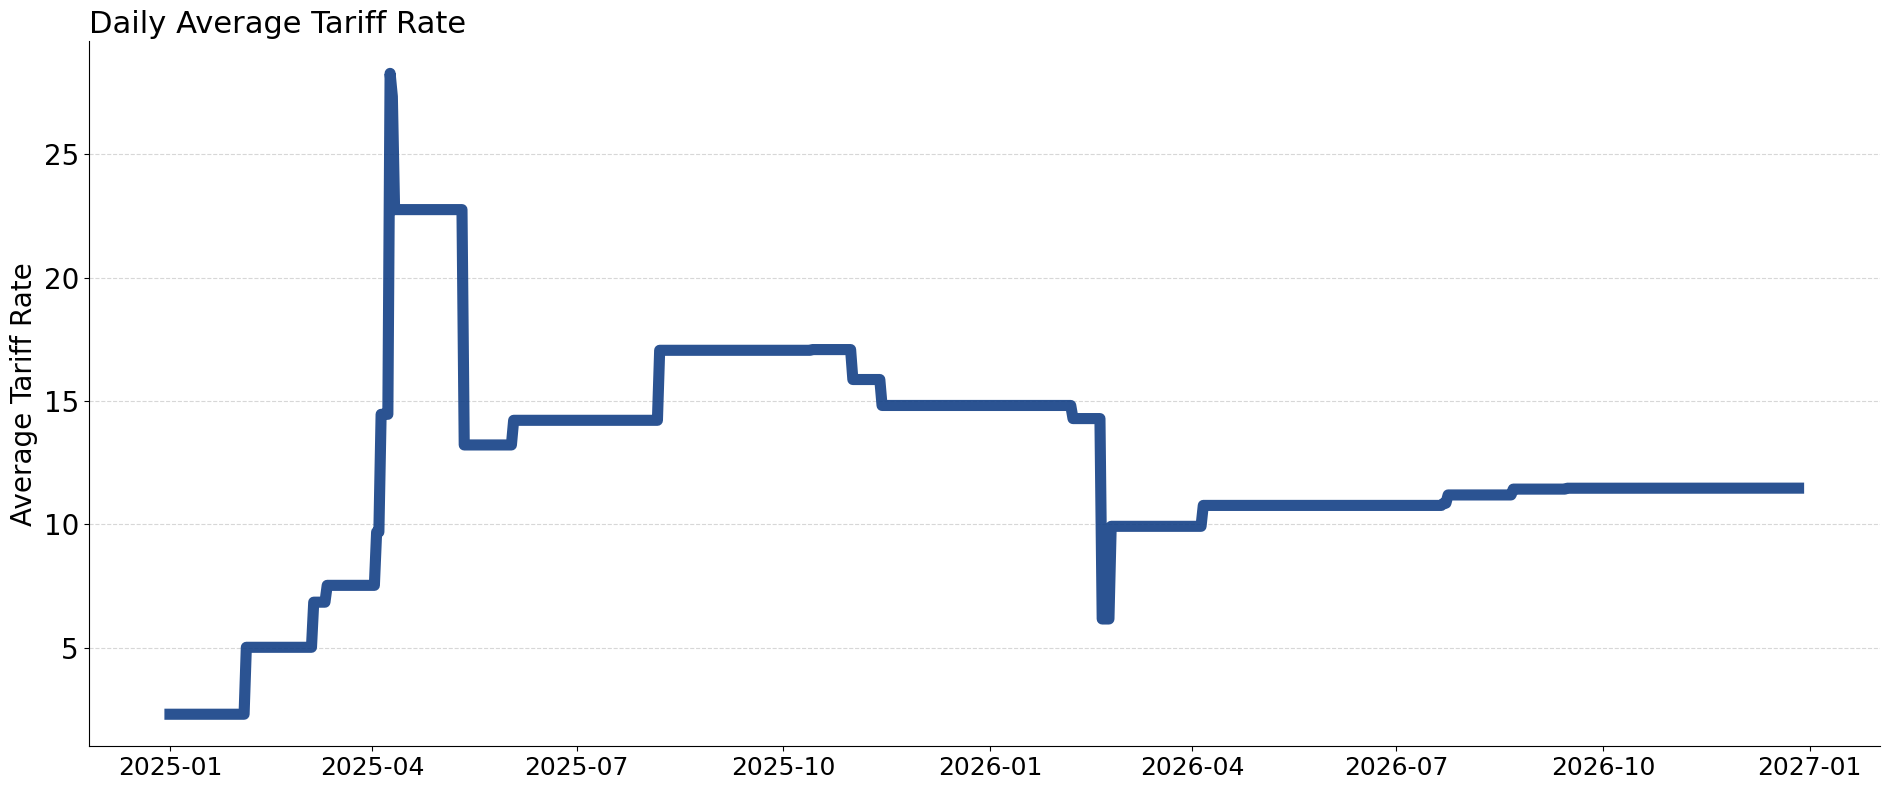

In [14]:
# Forward-fill to daily series.
# The series always runs BUFFER_DAYS past the run date rather than to a hardcoded
# end date, so the chart keeps a fixed buffer ahead of today without needing to be
# edited. Note the tail beyond the last policy date is forward-filled — it asserts
# "no further policy change", not observed data.
# The end is floored at the last policy date so a far-future action (e.g. the
# Jan 1, 2028 Annex III expiry) is never truncated out of the series.
BUFFER_DAYS = 60

weighted_avg_tariff = weighted_avg_tariff.set_index('date')
range_end = max(pd.Timestamp.today().normalize() + pd.Timedelta(days=BUFFER_DAYS),
                weighted_avg_tariff.index.max())
full_range = pd.date_range(weighted_avg_tariff.index.min(), range_end, freq='D')
weighted_avg_tariff_filled = (
    weighted_avg_tariff.reindex(full_range).ffill().reset_index()
    .rename(columns={'index': 'date'})
)

fig, ax = plt.subplots(figsize=(19, 8))
mike_blue = tuple(np.array([20, 64, 134]) / 255)

ax.plot(
    weighted_avg_tariff_filled['date'],
    weighted_avg_tariff_filled['import_weighted_avg_tariff'],
    alpha=0.90, color=mike_blue, linewidth=8, linestyle="-",
)

ax.set_ylabel('Average Tariff Rate', fontsize=20)
ax.set_title("Daily Average Tariff Rate", fontsize=22, loc="left")
ax.yaxis.grid(alpha=0.5, linestyle="--")
ax.tick_params(axis='x', labelsize=18)
ax.tick_params(axis='y', labelsize=20)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

plt.tight_layout()
plt.show()

In [15]:
tariffs_by_date.to_csv("country-by-time.csv")
weighted_avg_tariff_filled.to_csv("daily-tariff-latest-data.csv")

In [16]:
tariffs_by_date[tariffs_by_date["country_name"] == "CANADA"]

,country_name,effective tariff,total imports,2024 tariff
date,,,,
2025-02-04,CANADA,0.000000,4.116938e+11,0.100472
2025-03-06,CANADA,8.750000,4.116938e+11,0.100472
2025-03-12,CANADA,9.268593,4.116938e+11,0.100472
2025-04-03,CANADA,9.799271,4.116938e+11,0.100472
2025-04-05,CANADA,9.799271,4.116938e+11,0.100472
2025-04-09,CANADA,9.799271,4.116938e+11,0.100472
2025-04-10,CANADA,9.799271,4.116938e+11,0.100472
2025-04-11,CANADA,7.835008,4.116938e+11,0.100472
2025-05-12,CANADA,7.835008,4.116938e+11,0.100472


In [17]:
tariffs_by_date[tariffs_by_date["country_name"] == "TOTAL FOR ALL COUNTRIES"]

,country_name,effective tariff,total imports,2024 tariff
date,,,,


In [18]:
weighted_avg_tariff_filled.tail()

,date,import_weighted_avg_tariff
721,2026-12-23,11.463505
722,2026-12-24,11.463505
723,2026-12-25,11.463505
724,2026-12-26,11.463505
725,2026-12-27,11.463505
